# Mushroom Dataset — Exploratory Data Analysis

Explore the project dataset before preparing features or training models. This notebook describes class balance, missingness, data quality, feature distributions, and simple feature–target associations. Findings are exploratory and do not imply causation or real-world mushroom safety.

## 2. Imports and configuration

Load the libraries used throughout the notebook and set the target column. The source data is read directly from the project’s GitHub repository.

In [15]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TARGET = "class"
TARGET_LABEL_MAP = {"e": "edible", "p": "poisonous"}
DATASET_URL = "https://raw.githubusercontent.com/mjochen/CloudAI/master/Discussion%20topics/mushroom_project_dataset.csv"


## 3. Load and inspect the dataset

Read the published CSV, then check its dimensions and fields and preview a reproducible sample.

In [16]:
df = pd.read_csv(DATASET_URL)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Fix the sample seed so the notebook preview is reproducible.
print("\nRandom sample of 10 rows:")
display(df.sample(10, random_state=42))


Dataset shape: (5000, 13)

Columns:
['cap-diameter', 'stem-height', 'stem-width', 'spore-print-color', 'gill-color', 'habitat', 'season', 'ring-type', 'cap-shape', 'stem-surface', 'jumbled_noise_0', 'jumbled_noise_1', 'class']

Random sample of 10 rows:


,cap-diameter,stem-height,stem-width,spore-print-color,gill-color,habitat,season,ring-type,cap-shape,stem-surface,jumbled_noise_0,jumbled_noise_1,class
1501,8.34,NaN,19.67,NaN,w,d,a,f,s,NaN,x,x,p
2586,NaN,6.83,3.39,NaN,NaN,l,a,f,s,i,p,f,e
2653,7.25,5.32,NaN,NaN,f,d,u,f,x,NaN,f,NaN,e
1055,9.16,4.96,19.87,NaN,NaN,d,a,f,f,NaN,o,s,e
705,NaN,4.24,1.08,NaN,p,d,NaN,f,x,h,x,o,p
106,8.81,11.29,21.90,n,y,d,w,NaN,x,NaN,s,f,p
589,NaN,2.85,7.26,NaN,w,g,u,NaN,x,NaN,x,f,p
2468,4.20,6.11,7.94,NaN,o,d,a,f,f,t,p,x,e
2413,NaN,5.01,2.40,NaN,g,NaN,u,f,f,NaN,NaN,x,e
1600,NaN,6.72,8.36,NaN,f,d,a,f,s,NaN,x,o,e


## 4. Identify the target and feature types

Validate that the target exists and separate numerical from categorical predictors. The labels remain unchanged: e is edible and p is poisonous.

In [17]:
TARGET = "class"
if TARGET not in df.columns:
    raise KeyError(f"Expected target column {TARGET!r}; available columns: {df.columns.tolist()}")

TARGET_LABEL_MAP = {"e": "edible", "p": "poisonous"}
numeric_features = df.select_dtypes(include="number").columns.tolist()
categorical_features = [
    column for column in df.columns
    if column != TARGET and column not in numeric_features
]

print("Target label mapping")
display(pd.Series(TARGET_LABEL_MAP).rename_axis(TARGET).to_frame("meaning"))


Target label mapping


,meaning
class,
e,edible
p,poisonous


## 5. Examine class balance

Count each target class and calculate its share of the complete dataset.

In [18]:
# Class balance
class_summary = df[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame("count")
class_summary["percent"] = class_summary["count"] / len(df) * 100
print("Class balance")
display(class_summary)


Class balance


,count,percent
class,,
e,3107,62.14
p,1893,37.86


## 6. Check missingness and basic data quality

Summarize missing values, duplicates, column types, unique-value counts, and constant columns. These checks describe potential data issues; they do not modify the dataset.

In [19]:
# Missing values, sorted by prevalence
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100),
}).sort_values("missing_percent", ascending=False)
print("Missingness by feature")
display(missing_summary)

# Baseline dataset quality checks
print("Dataset shape:", df.shape)
print("\nDuplicate rows:", df.duplicated().sum())
print("\nDuplicate feature rows:")
print(df.drop(columns=[TARGET]).duplicated().sum())
print("\nUnique values per column:")
display(df.nunique(dropna=False).sort_values())
print("\nColumn data types:")
display(df.dtypes.to_frame("dtype"))
print("\nConstant columns:")
constant_cols = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]
print(constant_cols if constant_cols else "None")


Missingness by feature


,missing_count,missing_percent
spore-print-color,4740,94.80
stem-surface,3359,67.18
cap-diameter,2032,40.64
stem-height,1013,20.26
habitat,1004,20.08
gill-color,989,19.78
season,973,19.46
ring-type,577,11.54
cap-shape,406,8.12
jumbled_noise_0,406,8.12


Dataset shape: (5000, 13)

Duplicate rows: 0

Duplicate feature rows:
0

Unique values per column:


class                   2
season                  5
spore-print-color       8
cap-shape               8
jumbled_noise_0         8
jumbled_noise_1         8
habitat                 9
ring-type               9
stem-surface            9
gill-color             13
stem-height          1087
cap-diameter         1239
stem-width           2222
dtype: int64


Column data types:


,dtype
cap-diameter,float64
stem-height,float64
stem-width,float64
spore-print-color,str
gill-color,str
habitat,str
season,str
ring-type,str
cap-shape,str
stem-surface,str



Constant columns:
None


## 7. Compare missingness by class

Missingness may differ between edible and poisonous examples. This is descriptive evidence that can guide later preprocessing experiments.

In [20]:
# Missingness by class highlights whether absence itself is informative.
missing_by_class = (
    df.drop(columns=[TARGET])
    .isna()
    .groupby(df[TARGET])
    .mean()
    .T * 100
)
print("Missingness by target class (%)")
display(missing_by_class.round(2))


Missingness by target class (%)


class,e,p
cap-diameter,40.33,41.15
stem-height,20.28,20.23
stem-width,8.01,7.71
spore-print-color,95.72,93.29
gill-color,19.70,19.92
habitat,19.31,21.34
season,19.21,19.86
ring-type,11.84,11.04
cap-shape,8.40,7.66
stem-surface,69.78,62.92


## 8. Summarize numerical features and inspect outliers

Compare numerical summaries by class, examine their association with the encoded target, and flag possible IQR outliers for investigation. Outliers are not automatically removed.

In [21]:
# Numeric feature summaries split by class
if numeric_features:
    print("Numeric features by class")
    display(
        df.groupby(TARGET, observed=True)[numeric_features]
        .agg(["count", "mean", "median", "std"])
        .T
    )

    # Correlation of numerical features with the target. We encode the class to a binary target
    # so the correlation is interpretable: e=1, p=0.
    target_encoding = df[TARGET].map({"e": 1, "p": 0})
    numeric_target_corr = df[numeric_features].apply(lambda value: value.corr(target_encoding))
    print("Numeric feature correlation with target (e=1, p=0)")
    display(numeric_target_corr.sort_values(ascending=False).to_frame("correlation_with_target"))

    outlier_rows = []
    for feature in numeric_features:
        values = df[feature].dropna()
        if values.empty:
            continue
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outlier_mask = (values < lower_bound) | (values > upper_bound)
        outlier_rows.append({
            "feature": feature,
            "lower_IQR_bound": lower_bound,
            "upper_IQR_bound": upper_bound,
            "outlier_count": int(outlier_mask.sum()),
            "outlier_percent_of_nonmissing": outlier_mask.mean() * 100,
        })

    print("Potential numeric outliers (1.5 x IQR rule; investigate, do not auto-delete)")
    display(pd.DataFrame(outlier_rows).set_index("feature"))


Numeric features by class


class                          e            p
cap-diameter count   1854.000000  1114.000000
             mean       7.727994     6.218537
             median     6.555000     5.330000
             std        6.680776     4.445001
stem-height  count   2477.000000  1510.000000
             mean       6.957021     6.262099
             median     6.190000     5.725000
             std        3.533128     3.278544
stem-width   count   2858.000000  1747.000000
             mean      14.011491    11.042410
             median    12.265000     8.420000
             std       11.149066     9.380801

Numeric feature correlation with target (e=1, p=0)


,correlation_with_target
stem-width,0.135794
cap-diameter,0.122140
stem-height,0.097577


Potential numeric outliers (1.5 x IQR rule; investigate, do not auto-delete)


,lower_IQR_bound,upper_IQR_bound,outlier_count,outlier_percent_of_nonmissing
feature,,,,
cap-diameter,-3.6025,16.2175,134,4.514825
stem-height,0.3900,12.1500,271,6.797091
stem-width,-10.7250,33.7150,164,3.561346


## 9. Measure categorical association with the target

Cramér’s V provides a descriptive strength-of-association summary. It does not show causation or the direction of a relationship.

In [22]:
# Cramer's V ranks categorical features by descriptive association with the class.
# Missing values are retained as an explicit category. This is descriptive only; class-conditional
# bar plots provide the direction of the relationship and are more interpretable for presentation.
def cramers_v(feature_values, target_values):
    contingency = pd.crosstab(
        feature_values.astype("string").fillna("<missing>"),
        target_values.astype("string").fillna("<missing>"),
    ).to_numpy(dtype=float)
    total = contingency.sum()
    if total == 0 or min(contingency.shape) < 2:
        return np.nan
    expected = np.outer(contingency.sum(axis=1), contingency.sum(axis=0)) / total
    chi_square = np.divide(
        (contingency - expected) ** 2,
        expected,
        out=np.zeros_like(expected),
        where=expected > 0,
    ).sum()
    return float(np.sqrt(chi_square / (total * min(contingency.shape[0] - 1, contingency.shape[1] - 1))))

association_rows = [
    {"feature": feature, "cramers_v": cramers_v(df[feature], df[TARGET])}
    for feature in categorical_features
]
association = pd.DataFrame(association_rows).sort_values("cramers_v", ascending=False)
print("Categorical association with class (Cramer's V; descriptive, not causal)")
display(association)


Categorical association with class (Cramer's V; descriptive, not causal)


,feature,cramers_v
6,stem-surface,0.231790
5,cap-shape,0.165137
4,ring-type,0.161896
0,spore-print-color,0.134782
1,gill-color,0.127948
2,habitat,0.113143
3,season,0.074703
8,jumbled_noise_1,0.059540
7,jumbled_noise_0,0.034118


## 10. Check duplicate columns and numerical correlations

Look for identical columns and summarize pairwise numerical correlations to identify possible redundancy.

In [23]:
# Check for columns with exactly identical values, including matching missing values.
duplicate_pairs = []
for index, left in enumerate(df.columns):
    for right in df.columns[index + 1:]:
        if df[left].equals(df[right]):
            duplicate_pairs.append((left, right))
print("Exact duplicate column pairs:")
print(duplicate_pairs if duplicate_pairs else "None found")

# Numerical correlations
if len(numeric_features) >= 2:
    correlation = df[numeric_features].corr()
    print("Numeric feature correlation matrix")
    display(correlation)


Exact duplicate column pairs:
None found
Numeric feature correlation matrix


,cap-diameter,stem-height,stem-width
cap-diameter,1.000000,0.398651,0.623871
stem-height,0.398651,1.000000,0.439085
stem-width,0.623871,0.439085,1.000000


## 11. Visualize class balance and categorical associations

The first figure combines class counts with categorical association strength. These plots summarize the complete dataset and are exploratory.

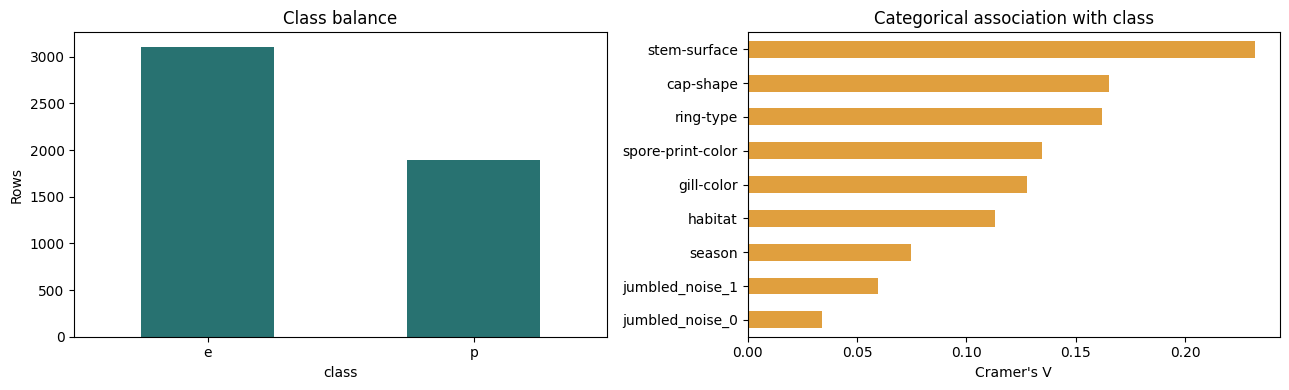

In [24]:
# Visual comparisons
class_labels = df[TARGET].dropna().unique().tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
class_summary["count"].plot(kind="bar", ax=axes[0], color="#287271")
axes[0].set_title("Class balance")
axes[0].set_xlabel(TARGET)
axes[0].set_ylabel("Rows")
axes[0].tick_params(axis="x", rotation=0)

if not association.empty:
    association.sort_values("cramers_v").plot(
        kind="barh", x="feature", y="cramers_v", legend=False,
        ax=axes[1], color="#e09f3e",
    )
    axes[1].set_title("Categorical association with class")
    axes[1].set_xlabel("Cramer's V")
    axes[1].set_ylabel("")
plt.tight_layout()
plt.show()


## 12. Compare categorical feature distributions by class

Stacked bars show the class composition within each category. Missing values are shown as their own category so examples are retained.

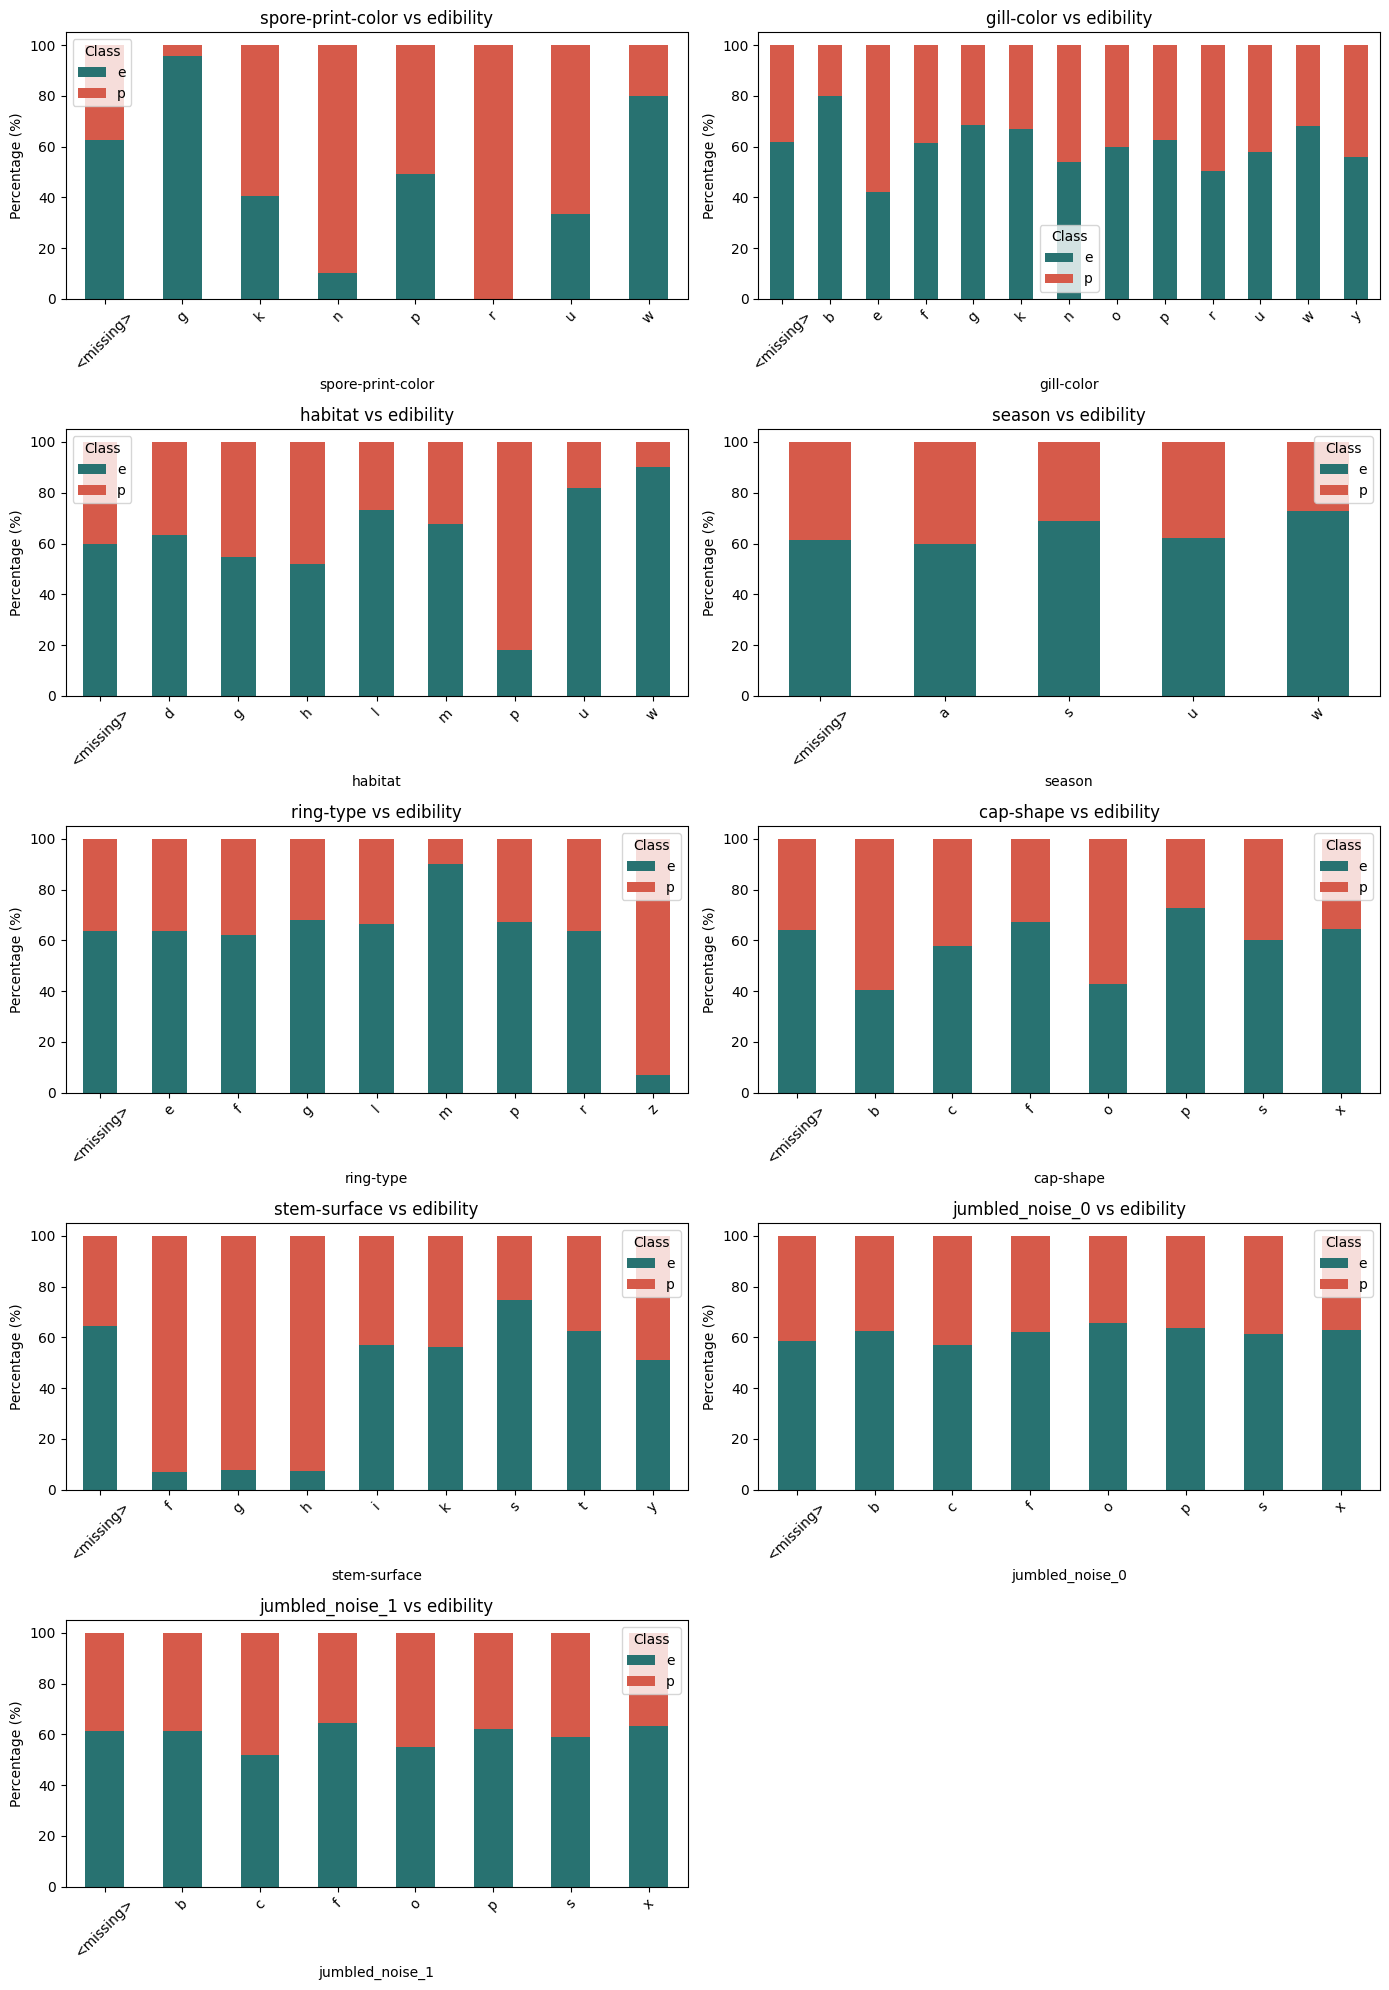

In [25]:
# Class-conditional categorical plots show the direction of the relationship, not just strength.
if categorical_features:
    ncols = 2
    nrows = math.ceil(len(categorical_features) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows), squeeze=False)
    axes = axes.flatten()

    for ax, feature in zip(axes, categorical_features):
        temp = df[[feature, TARGET]].copy()
        temp[feature] = temp[feature].fillna("<missing>")
        proportions = pd.crosstab(temp[feature], temp[TARGET], normalize="index") * 100
        proportions.plot(
            kind="bar",
            stacked=True,
            ax=ax,
            color=["#287271", "#d65a4a"],
        )
        ax.set_title(f"{feature} vs edibility")
        ax.set_xlabel(feature)
        ax.set_ylabel("Percentage (%)")
        ax.tick_params(axis="x", rotation=45)
        ax.legend(title="Class")

    for ax in axes[len(categorical_features):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()


## 13. Visualize missingness by class

Compare feature missingness percentages between edible and poisonous examples.

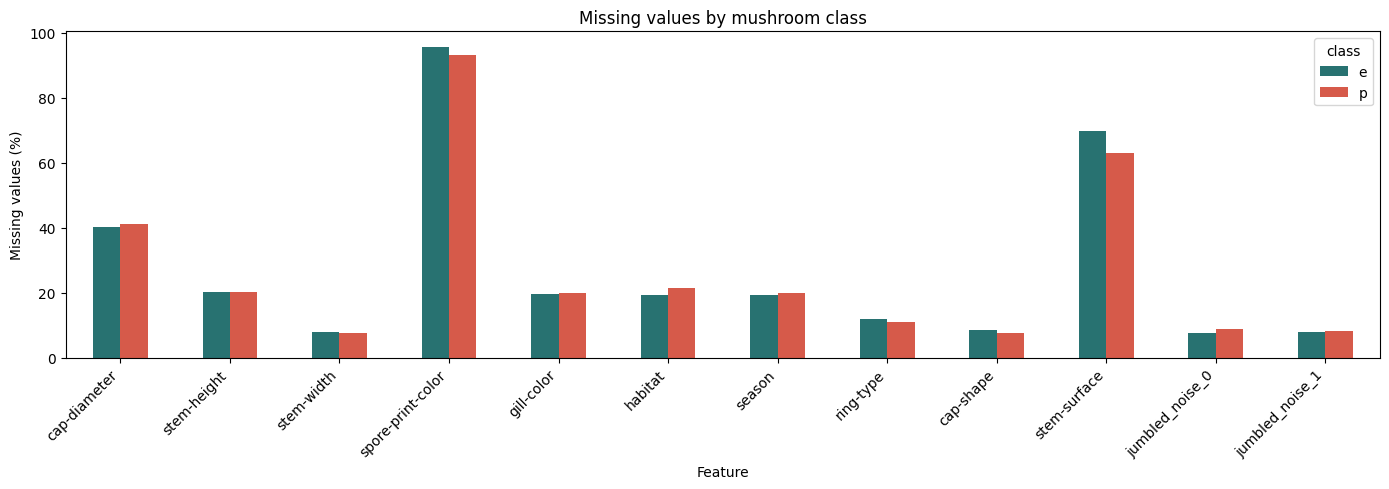

In [26]:
# Show missingness by class as a second view of the target relationship; this helps decide whether
# missing-value indicators should be tested later during preprocessing.
missing_by_class.plot(
    kind="bar",
    figsize=(14, 5),
    color=["#287271", "#d65a4a"],
)
plt.title("Missing values by mushroom class")
plt.ylabel("Missing values (%)")
plt.xlabel("Feature")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 14. Compare numerical distributions by class

Density histograms show the distributions of non-missing numerical values for each target class.

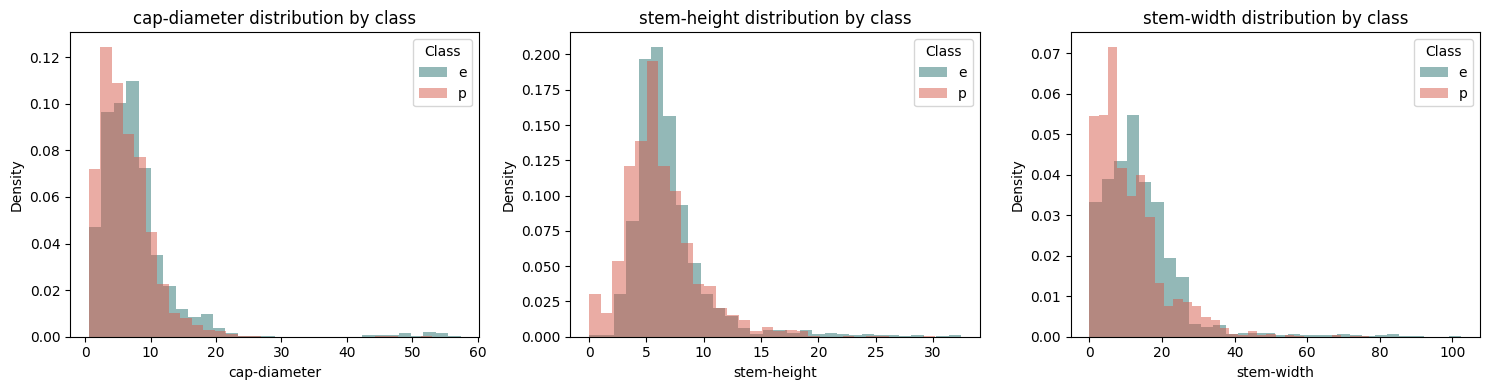

In [27]:
if numeric_features:
    fig, axes = plt.subplots(
        1, len(numeric_features),
        figsize=(5 * len(numeric_features), 4),
        squeeze=False,
    )
    for axis, feature in zip(axes[0], numeric_features):
        for label, color in [("e", "#287271"), ("p", "#d65a4a")]:
            values = df.loc[df[TARGET] == label, feature].dropna()
            axis.hist(
                values,
                bins=30,
                density=True,
                alpha=0.5,
                label=label,
                color=color,
            )
        axis.set_title(f"{feature} distribution by class")
        axis.set_xlabel(feature)
        axis.set_ylabel("Density")
        axis.legend(title="Class")
    plt.tight_layout()
    plt.show()


## 15. Compare numerical spreads by class

Boxplots compare typical ranges by class. Extreme points are hidden here for readability; the earlier IQR summary retains outlier counts for review.

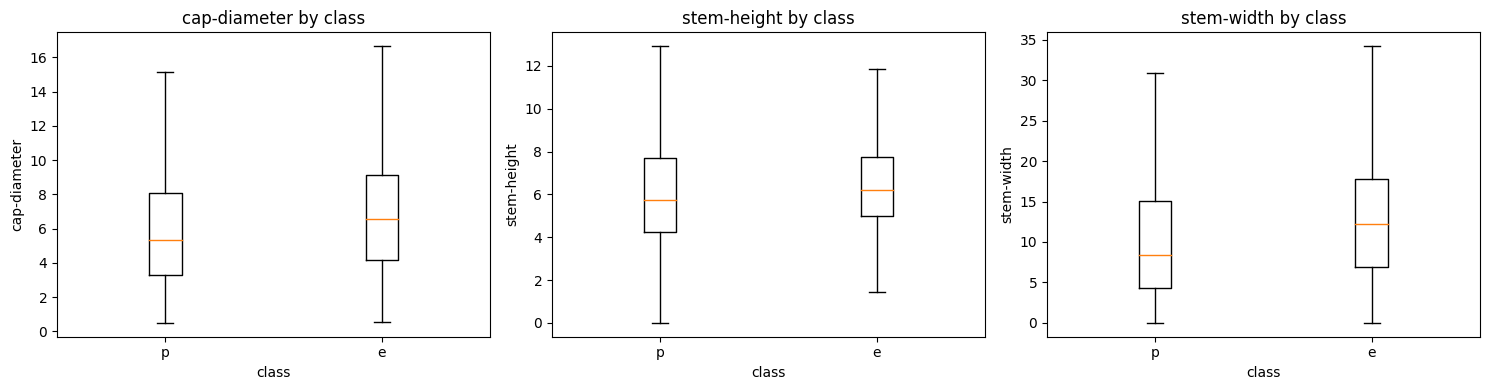

In [28]:
if numeric_features:
    fig, axes = plt.subplots(
        1, len(numeric_features),
        figsize=(5 * len(numeric_features), 4),
        squeeze=False,
    )
    for axis, feature in zip(axes[0], numeric_features):
        values_by_class = [
            df.loc[df[TARGET] == label, feature].dropna().to_numpy()
            for label in class_labels
        ]
        # showfliers=False keeps the visual emphasis on the typical spread while the IQR summary
        # above still flags unusual measurements for review instead of auto-removing them.
        axis.boxplot(values_by_class, labels=[str(label) for label in class_labels], showfliers=False)
        axis.set_title(f"{feature} by class")
        axis.set_xlabel(TARGET)
        axis.set_ylabel(feature)
    plt.tight_layout()
    plt.show()


## 16. Visualize numerical feature correlations

The heatmap shows pairwise Pearson correlations between numerical features, not causal relationships.

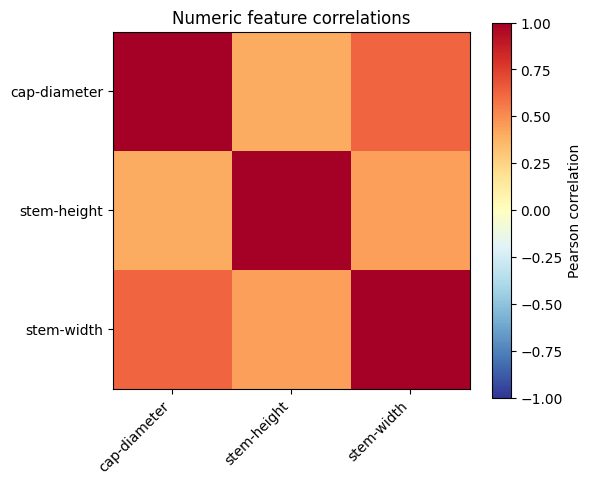

In [29]:
if len(numeric_features) >= 2:
    figure, axis = plt.subplots(figsize=(6, 5))
    image = axis.imshow(correlation, cmap="RdYlBu_r", vmin=-1, vmax=1)
    axis.set_xticks(range(len(numeric_features)), numeric_features, rotation=45, ha="right")
    axis.set_yticks(range(len(numeric_features)), numeric_features)
    axis.set_title("Numeric feature correlations")
    figure.colorbar(image, ax=axis, label="Pearson correlation")
    plt.tight_layout()
    plt.show()
